# 02 - Anomaly types (exploratory analysis)

Works on `data/processed/transactions_clean.parquet` (output of `01_preprocessing`) with **DuckDB**, so the 10M rows are never loaded into memory all at once. Each analysis is a SQL query that returns a small pandas table, followed by a chart.

- `tx` = the full clean data (all 21 columns, read straight from the Parquet file)
- `base` = a narrow working table without the 4 free-text columns, stored in `data/interim/eda.duckdb` (built once, reused afterwards)
- Charts are saved to `reports/figures/` for the dashboard and slides.

**First time only:** `pip install duckdb matplotlib` inside `.venv`. Run the cells top to bottom.

## 0. Setup

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"

PARQUET = ROOT / "data" / "processed" / "transactions_clean.parquet"
DB_FILE = ROOT / "data" / "interim" / "eda.duckdb"  # working database (gitignored)
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert PARQUET.exists(), f"Missing {PARQUET} - run 01_preprocessing first"

con = duckdb.connect(str(DB_FILE))
con.execute("SET preserve_insertion_order = false")
con.execute("SET TimeZone = 'UTC'")  # hours and dates in UTC, same as src/eda.py
# If the laptop runs out of memory, uncomment and lower this:
# con.execute("SET memory_limit = '3GB'")

con.execute(f"CREATE OR REPLACE VIEW tx AS SELECT * FROM read_parquet('{PARQUET.as_posix()}')")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query with DuckDB and return the result as a pandas DataFrame."""
    return con.sql(sql).df()


def save(fig, name: str) -> None:
    """Save a chart to reports/figures/<name>.png for the dashboard and slides."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("DuckDB", duckdb.__version__)

Project root: c:\Users\User\Documents\liqi-datathon
DuckDB 2.0.0


### Working table `base`
All structured columns plus `ep` (timestamp as epoch seconds) and a `row_id`. The free-text columns (`*_details`, `*_tokens`) are left out to keep it fast; use the `tx` view when you need them. Building it takes a few minutes the first time only.

In [2]:
tables = con.sql("SELECT table_name FROM information_schema.tables").df()["table_name"].tolist()
if "base" not in tables:
    con.execute("""
        CREATE TABLE base AS
        SELECT row_number() OVER ()           AS row_id,
               epoch_seconds                  AS ts,
               epoch(epoch_seconds)::BIGINT   AS ep,
               currency_code, usd_amount,
               ordering_bic8, beneficiary_bic8, bic8_path,
               total_duration, continuity_qflag,
               currency_conversion_count, participant_count, transaction_type_code,
               ordering_account, beneficiary_account,
               ordering_type, beneficiary_type,
               anomaly_type, is_anomaly
        FROM tx
    """)
n_base = q("SELECT count(*) AS n FROM base").loc[0, "n"]
print(f"{n_base:,} rows in base")

10,000,000 rows in base


## 1. Sanity check
These numbers must match the profiling report. If an assert fails, the Parquet file is incomplete.

In [3]:
checks = q("""
    SELECT count(*)            AS rows,
           count(anomaly_type) AS anomalies,
           sum(is_anomaly)     AS is_anomaly_sum,
           min(ts)             AS first_payment,
           max(ts)             AS last_payment,
           sum(usd_amount)     AS total_usd
    FROM base
""")
assert checks.loc[0, "rows"] == 10_000_000
assert checks.loc[0, "anomalies"] == 7_006 == checks.loc[0, "is_anomaly_sum"]
checks

,rows,anomalies,is_anomaly_sum,first_payment,last_payment,total_usd
0,10000000,7006,7006.0,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00,9.720410e+11


## A. Anomaly types

Definitions from the case study: **ROMANCE_SCAM** (a consumer repeatedly sends money to a fake partner), **CEO_SCAM** (a business pays a fraudster after a spoofed CEO request), **ACCOUNT_REPLACEMENT_SCAM** (a real invoice with the account number swapped), **FAT_FINGER_MISTAKE** (comma separator misplaced in the amount), **DUPLICATE_PAYMENT** (accidental repeat). **CUSTOMER_RECALL** is in the data but *not defined* in the brief (question sent to the mentor).

### Hypotheses (written before testing)
| ID | Hypothesis | Test |
|---|---|---|
| H-A1 | Romance scams are sent only by consumers; CEO scams only by businesses | % consumer senders per type (A1) |
| H-A2 | A romance victim pays the same beneficiary several times in a short burst, with rising amounts | Payments per victim, time span, amount by payment number (A2) |
| H-A3 | A duplicate is an exact copy (same sender, receiver, amount, currency) sent shortly after the original, and repeats without the label are rare | Identical-payment groups, labelled vs not, time gap (A3) |
| H-A4 | A fat-finger amount is off from the sender's usual amount by a power of 10 | log10(amount / sender's normal median) vs normal payments (A4) |
| H-A5 | CEO and account-replacement scams go to a payee the sender has never paid normally | % of pairs with normal payment history (A5) |
| H-A6 | Scam rows are generated separately from normal traffic, so they lack the noise normal rows have | Path endpoint vs BIC mismatch rate (A6) |
| H-A7 | Scams take longer to settle, and this is not explained by the route | Duration by type, within the same transaction type (A7) |
| H-A8 | A fat-finger amount is an exact power-of-10 copy of an earlier payment to the same payee, or (in USD) the moved decimal point leaves extra trailing zeros | Copy test + trailing zeros in USD amounts (A8) |
| H-A9 | Account-replacement amounts look like the sender's normal invoices; CEO-scam amounts are larger than usual | Amount ÷ sender's usual amount vs a normal baseline (A9) |
| H-A10 | A labelled duplicate repeats the whole payment, including bank path and duration, within 2 hours | Groups identical in 6 fields (A10) |
| H-A11 | CUSTOMER_RECALL differs from normal payments in at least one attribute | 12 attribute tests with correction + duration control (A11) |
| H-A12 | Some anomaly types happen at unusual times | UTC hour bands and weekend share per type (A12) |

### A1. Who sends and receives each anomaly type (H-A1)

In [4]:
a1 = q("""
    SELECT coalesce(anomaly_type, '(normal)')                   AS anomaly_type,
           count(*)                                             AS n,
           round(100 * avg((ordering_type = 'C')::INT), 1)      AS pct_sender_consumer,
           round(100 * avg((beneficiary_type = 'C')::INT), 1)   AS pct_receiver_consumer
    FROM base
    GROUP BY 1
    ORDER BY n DESC
""")
a1

,anomaly_type,n,pct_sender_consumer,pct_receiver_consumer
0,(normal),9992994,21.2,71.2
1,ROMANCE_SCAM,2476,100.0,73.1
2,FAT_FINGER_MISTAKE,1940,20.5,71.9
3,CEO_SCAM,945,0.0,72.3
4,DUPLICATE_PAYMENT,679,19.7,74.5
5,ACCOUNT_REPLACEMENT_SCAM,649,21.7,73.5
6,CUSTOMER_RECALL,317,22.4,73.2


In [5]:
pairs = q("""
    SELECT coalesce(anomaly_type, '(normal)') AS anomaly_type,
           ordering_type || '→' || beneficiary_type AS sender_to_receiver,
           count(*) AS n
    FROM base GROUP BY 1, 2
""").pivot(index="anomaly_type", columns="sender_to_receiver", values="n").fillna(0).astype(int)
pairs_pct = (pairs.div(pairs.sum(axis=1), axis=0) * 100).round(1)
pairs_pct  # % of each row (B = business, C = consumer)

sender_to_receiver,B→B,B→C,C→B,C→C
anomaly_type,,,,
(normal),22.7,56.0,6.1,15.1
ACCOUNT_REPLACEMENT_SCAM,21.3,57.0,5.2,16.5
CEO_SCAM,27.7,72.3,0.0,0.0
CUSTOMER_RECALL,19.9,57.7,6.9,15.5
DUPLICATE_PAYMENT,22.4,57.9,3.1,16.6
FAT_FINGER_MISTAKE,22.9,56.6,5.2,15.3
ROMANCE_SCAM,0.0,0.0,26.9,73.1


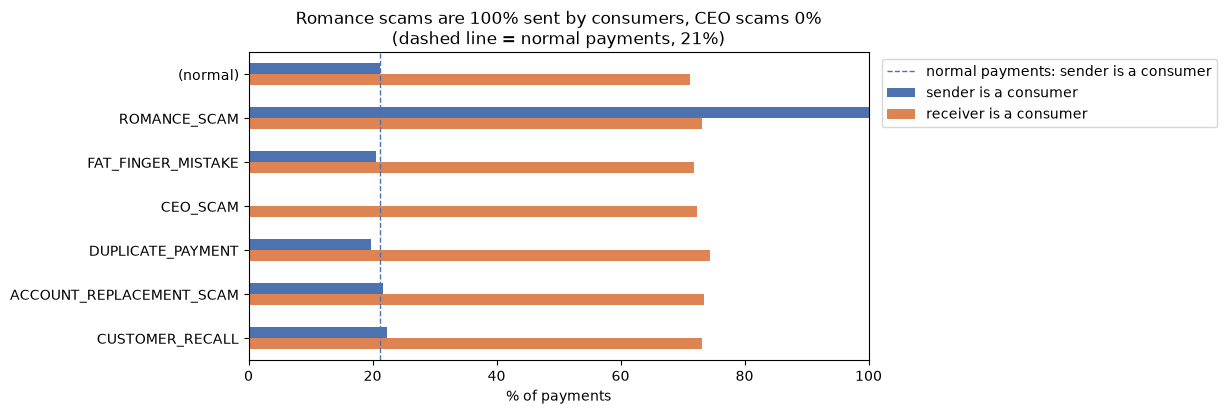

In [6]:
d = (a1.set_index("anomaly_type")[["pct_sender_consumer", "pct_receiver_consumer"]]
        .rename(columns={"pct_sender_consumer": "sender is a consumer",
                         "pct_receiver_consumer": "receiver is a consumer"}))
fig, ax = plt.subplots(figsize=(8, 4))
d.plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.axvline(d.loc["(normal)", "sender is a consumer"], color="#4C72B0", ls="--", lw=1,
           label="normal payments: sender is a consumer")
ax.set_xlabel("% of payments")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Romance scams are 100% sent by consumers, CEO scams 0%\n(dashed line = normal payments, 21%)")
save(fig, "A1_anomaly_party_types")
plt.show()

### A2. Romance scams: repeated payments to one beneficiary (H-A2)

In [7]:
rom = q("""
    SELECT ordering_account, beneficiary_account, ep, usd_amount,
           row_number() OVER (PARTITION BY ordering_account, beneficiary_account ORDER BY ep, row_id) AS payment_no
    FROM base
    WHERE anomaly_type = 'ROMANCE_SCAM'
""")
per_victim = (rom.sort_values("payment_no")
                 .groupby(["ordering_account", "beneficiary_account"])
                 .agg(n_payments=("usd_amount", "size"),
                      first_usd=("usd_amount", "first"),
                      last_usd=("usd_amount", "last"),
                      span_min=("ep", lambda s: (s.max() - s.min()) / 60),
                      strictly_rising=("usd_amount", lambda s: bool((s.diff().dropna() > 0).all())))
                 .reset_index())
summary = pd.Series({
    "romance payments": len(rom),
    "victim -> beneficiary pairs": len(per_victim),
    "distinct victims (senders)": rom["ordering_account"].nunique(),
    "distinct beneficiaries": rom["beneficiary_account"].nunique(),
    "payments per victim (min / median / max)": f"{per_victim.n_payments.min()} / {per_victim.n_payments.median():.0f} / {per_victim.n_payments.max()}",
    "time span per victim, minutes (median)": round(per_victim.span_min.median(), 1),
    "time span per victim, minutes (90th pct)": round(per_victim.span_min.quantile(0.9), 1),
    "% of consecutive payments larger than the previous one": round(100 * (rom.sort_values("payment_no").groupby(["ordering_account", "beneficiary_account"]).usd_amount.diff().dropna() > 0).mean(), 1),
    "% of victims whose amounts rise every single time": round(100 * per_victim.strictly_rising.mean(), 1),
    "last / first amount (median)": round((per_victim.last_usd / per_victim.first_usd).median(), 1),
})
summary.to_frame("value")

,value
romance payments,2476
victim -> beneficiary pairs,500
distinct victims (senders),500
distinct beneficiaries,378
payments per victim (min / median / max),2 / 5 / 8
"time span per victim, minutes (median)",17.8
"time span per victim, minutes (90th pct)",40.4
% of consecutive payments larger than the previous one,83.1
% of victims whose amounts rise every single time,44.8
last / first amount (median),4.9


In [8]:
victims_per_bene = rom.groupby("beneficiary_account")["ordering_account"].nunique()
victims_per_bene.value_counts().sort_index().rename_axis("victims per beneficiary").to_frame("beneficiaries")

,beneficiaries
victims per beneficiary,
1,288
2,67
3,17
4,4
5,1
6,1


In [9]:
# Median amount by position in the victim's sequence (the numbers behind the right-hand chart)
(rom.groupby("payment_no")["usd_amount"]
    .agg(victims="size", median_usd="median")
    .round(2)
    .rename_axis("payment number"))

,victims,median_usd
payment number,,
1,500,33.27
2,500,54.34
3,439,87.93
4,344,143.82
5,280,205.74
6,209,349.81
7,135,543.96
8,69,1925.47


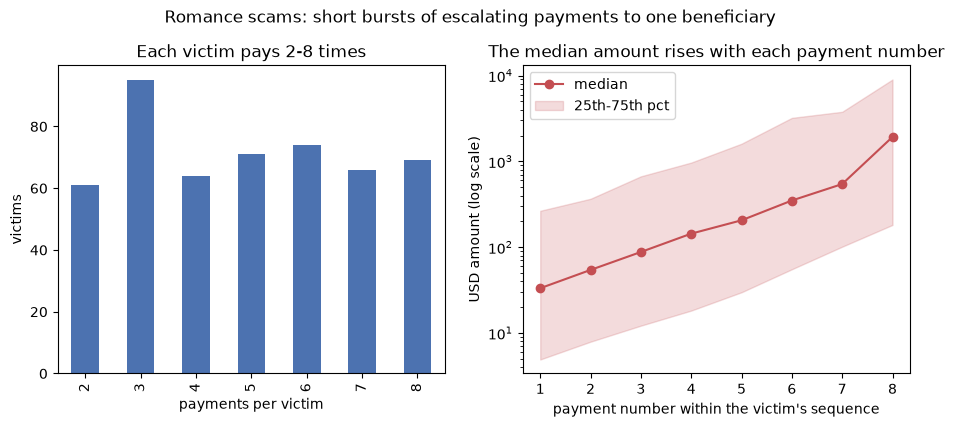

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
per_victim.n_payments.value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_xlabel("payments per victim")
axes[0].set_ylabel("victims")
axes[0].set_title("Each victim pays 2-8 times")

by_no = rom.groupby("payment_no")["usd_amount"].quantile([0.25, 0.5, 0.75]).unstack()
axes[1].plot(by_no.index, by_no[0.5], marker="o", color="#C44E52", label="median")
axes[1].fill_between(by_no.index, by_no[0.25], by_no[0.75], alpha=0.2, color="#C44E52", label="25th-75th pct")
axes[1].set_yscale("log")
axes[1].set_xlabel("payment number within the victim's sequence")
axes[1].set_ylabel("USD amount (log scale)")
axes[1].set_title("The median amount rises with each payment number")
axes[1].legend()
fig.suptitle("Romance scams: short bursts of escalating payments to one beneficiary", y=1.02)
save(fig, "A2_romance_bursts")
plt.show()

### A3. Duplicate payments: identical copies (H-A3)

In [11]:
dup = q("""
    WITH g AS (
        SELECT ordering_account, beneficiary_account, usd_amount, currency_code,
               count(*)                                                AS n_copies,
               count(*) FILTER (WHERE anomaly_type = 'DUPLICATE_PAYMENT') AS n_dup_label,
               max(ep) - min(ep)                                       AS spread_s
        FROM base
        GROUP BY ALL
        HAVING count(*) > 1
    )
    SELECT *,
           CASE WHEN n_dup_label = n_copies THEN 'all copies labelled DUPLICATE'
                WHEN n_dup_label = 0        THEN 'no copy labelled DUPLICATE'
                ELSE 'partly labelled' END AS group_kind
    FROM g
""")
(dup.groupby("group_kind")
    .agg(groups=("n_copies", "size"), rows=("n_copies", "sum"),
         copies_min=("n_copies", "min"), copies_max=("n_copies", "max"),
         spread_s_median=("spread_s", "median"), spread_s_max=("spread_s", "max")))

,groups,rows,copies_min,copies_max,spread_s_median,spread_s_max
group_kind,,,,,,
all copies labelled DUPLICATE,185,679,2,5,4023.0,7043
no copy labelled DUPLICATE,2439,5570,2,13,1807202.0,7805546


In [12]:
labelled = dup[dup.group_kind == "all copies labelled DUPLICATE"]
print("Copies per duplicate group:")
print(labelled.n_copies.value_counts().sort_index().to_string())
n_dup_total = q("SELECT count(*) AS n FROM base WHERE anomaly_type = 'DUPLICATE_PAYMENT'").loc[0, "n"]
print(f"\nDUPLICATE_PAYMENT rows inside these groups: {labelled.n_dup_label.sum()} of {n_dup_total}")

Copies per duplicate group:
n_copies
2    37
3    43
4    49
5    56

DUPLICATE_PAYMENT rows inside these groups: 679 of 679


In [13]:
# How well does "identical copy within 2 hours" separate labelled duplicates from unlabelled repeats?
window = 2 * 3600
(dup.assign(within_2h=dup.spread_s <= window)
    .groupby("group_kind")
    .agg(groups=("within_2h", "size"), within_2h=("within_2h", "sum"),
         spread_s_min=("spread_s", "min"), mean_usd=("usd_amount", "mean")))

,groups,within_2h,spread_s_min,mean_usd
group_kind,,,,
all copies labelled DUPLICATE,185,185,203,117426.797027
no copy labelled DUPLICATE,2439,139,9,34791.341726


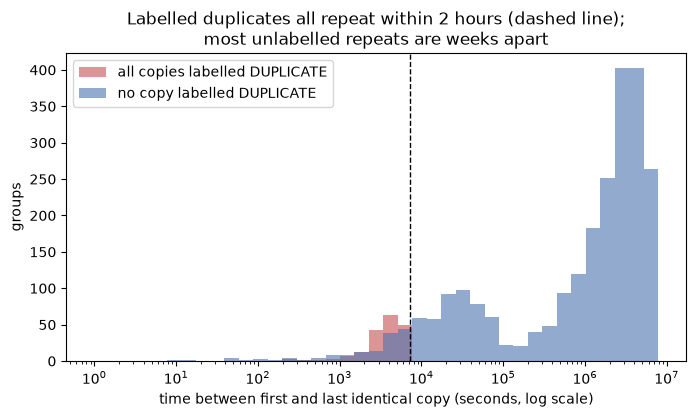

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(dup.spread_s.max() + 1), 40)
for kind, color in [("all copies labelled DUPLICATE", "#C44E52"), ("no copy labelled DUPLICATE", "#4C72B0")]:
    ax.hist(dup.loc[dup.group_kind == kind, "spread_s"] + 1, bins=bins, alpha=0.6, label=kind, color=color)
ax.set_xscale("log")
ax.set_xlabel("time between first and last identical copy (seconds, log scale)")
ax.set_ylabel("groups")
ax.legend()
ax.axvline(2 * 3600, color="black", ls="--", lw=1)
ax.set_title("Labelled duplicates all repeat within 2 hours (dashed line);\nmost unlabelled repeats are weeks apart")
save(fig, "A3_duplicate_time_gap")
plt.show()

### A4. Fat-finger mistakes: amount off by a power of 10 (H-A4)

In [15]:
ff = q("""
    WITH med AS (
        SELECT ordering_account, median(usd_amount) AS sender_median_usd
        FROM base
        WHERE anomaly_type IS NULL
        GROUP BY 1
    )
    SELECT coalesce(b.anomaly_type, '(normal sample)') AS kind,
           b.usd_amount, m.sender_median_usd,
           log10(b.usd_amount / m.sender_median_usd)   AS log10_ratio
    FROM base b
    JOIN med m USING (ordering_account)
    WHERE b.anomaly_type = 'FAT_FINGER_MISTAKE'
       OR (b.anomaly_type IS NULL AND b.row_id % 200 = 0)   -- 0.5% sample of normal payments as baseline
""")
ff["magnitude"] = ff.log10_ratio.round().astype(int)
pd.crosstab(ff.magnitude, ff.kind, normalize="columns").mul(100).round(1)  # % of each column

kind,(normal sample),FAT_FINGER_MISTAKE
magnitude,,
-4,0.0,0.8
-3,0.4,4.7
-2,5.1,8.7
-1,23.6,6.3
0,42.0,7.0
1,22.9,15.2
2,5.5,18.7
3,0.5,18.6
4,0.0,12.9


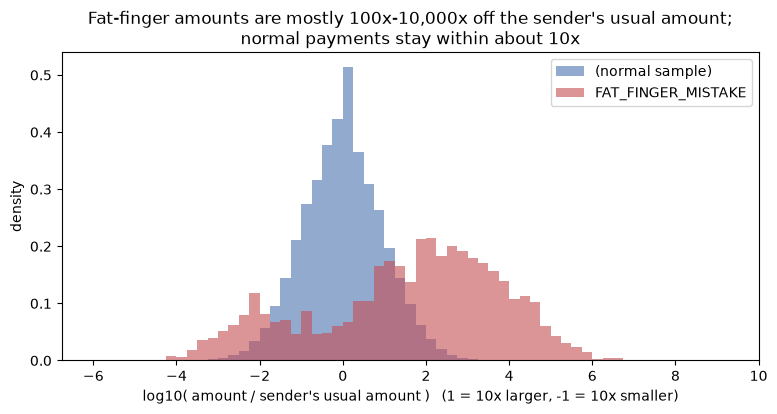

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(-6, 9.5, 0.25)
for kind, color in [("(normal sample)", "#4C72B0"), ("FAT_FINGER_MISTAKE", "#C44E52")]:
    ax.hist(ff.loc[ff.kind == kind, "log10_ratio"], bins=bins, density=True, alpha=0.6, label=kind, color=color)
ax.set_xlabel("log10( amount / sender's usual amount )   (1 = 10x larger, -1 = 10x smaller)")
ax.set_ylabel("density")
ax.legend()
ax.set_title("Fat-finger amounts are mostly 100x-10,000x off the sender's usual amount;\nnormal payments stay within about 10x")
save(fig, "A4_fat_finger_magnitude")
plt.show()

In [17]:
# Evidence for R-A4: the largest payments in the whole dataset and their labels
top12 = q("""
    SELECT usd_amount, currency_code, coalesce(anomaly_type, '(normal)') AS anomaly_type
    FROM base
    ORDER BY usd_amount DESC
    LIMIT 12
""")
print(f"Fat-finger mistakes among the 12 largest payments: {(top12.anomaly_type == 'FAT_FINGER_MISTAKE').sum()} of 12")
top12

Fat-finger mistakes among the 12 largest payments: 12 of 12


,usd_amount,currency_code,anomaly_type
0,1.566413e+10,EUR,FAT_FINGER_MISTAKE
1,1.389851e+10,EUR,FAT_FINGER_MISTAKE
2,1.284643e+10,ILS,FAT_FINGER_MISTAKE
3,8.910968e+09,HKD,FAT_FINGER_MISTAKE
4,8.297209e+09,RON,FAT_FINGER_MISTAKE
5,7.362502e+09,EUR,FAT_FINGER_MISTAKE
6,4.585373e+09,ILS,FAT_FINGER_MISTAKE
7,4.287956e+09,USD,FAT_FINGER_MISTAKE
8,3.596947e+09,EUR,FAT_FINGER_MISTAKE
9,3.484752e+09,CAD,FAT_FINGER_MISTAKE


### A5. New payee: has the sender ever paid this beneficiary normally? (H-A5)

In [18]:
a5 = q("""
    WITH s AS (
        SELECT anomaly_type,
               count(*) FILTER (WHERE anomaly_type IS NULL)
                   OVER (PARTITION BY ordering_account, beneficiary_account)
               - (anomaly_type IS NULL)::INT AS other_normal_payments_same_pair
        FROM base
    )
    SELECT coalesce(anomaly_type, '(normal)') AS anomaly_type,
           count(*) AS n,
           round(100 * avg((other_normal_payments_same_pair > 0)::INT), 1) AS pct_pair_has_normal_history
    FROM s
    GROUP BY 1
    ORDER BY pct_pair_has_normal_history
""")
a5

,anomaly_type,n,pct_pair_has_normal_history
0,ACCOUNT_REPLACEMENT_SCAM,649,0.0
1,ROMANCE_SCAM,2476,0.0
2,CEO_SCAM,945,0.2
3,DUPLICATE_PAYMENT,679,19.6
4,(normal),9992994,23.6
5,FAT_FINGER_MISTAKE,1940,23.7
6,CUSTOMER_RECALL,317,26.8


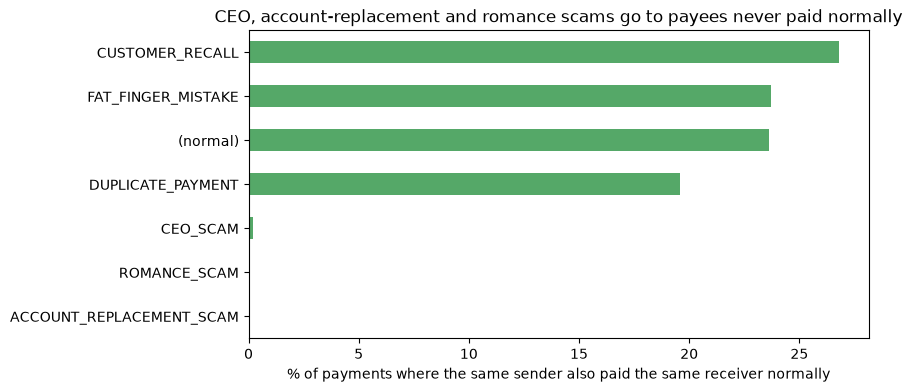

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
a5.set_index("anomaly_type")["pct_pair_has_normal_history"].plot.barh(ax=ax, color="#55A868")
ax.set_xlabel("% of payments where the same sender also paid the same receiver normally")
ax.set_ylabel("")
ax.set_title("CEO, account-replacement and romance scams go to payees never paid normally")
save(fig, "A5_new_payee")
plt.show()

### A6. Path endpoints vs BIC columns (H-A6)
In normal rows the first bank in `bic8_path` sometimes differs from `ordering_bic8`, and the last from `beneficiary_bic8`. Does the same happen in anomalies?

In [20]:
a6 = q("""
    SELECT coalesce(anomaly_type, '(normal)') AS anomaly_type,
           count(*) AS n,
           round(100 * avg((split_part(bic8_path, ';', 1) <> ordering_bic8)::INT), 2)          AS pct_first_hop_differs,
           round(100 * avg((string_split(bic8_path, ';')[-1] <> beneficiary_bic8)::INT), 2)    AS pct_last_hop_differs
    FROM base
    GROUP BY 1
    ORDER BY n DESC
""")
a6

,anomaly_type,n,pct_first_hop_differs,pct_last_hop_differs
0,(normal),9992994,4.99,4.99
1,ROMANCE_SCAM,2476,0.00,0.00
2,FAT_FINGER_MISTAKE,1940,5.15,5.52
3,CEO_SCAM,945,6.14,0.00
4,DUPLICATE_PAYMENT,679,5.15,4.42
5,ACCOUNT_REPLACEMENT_SCAM,649,5.24,0.00
6,CUSTOMER_RECALL,317,4.42,4.73


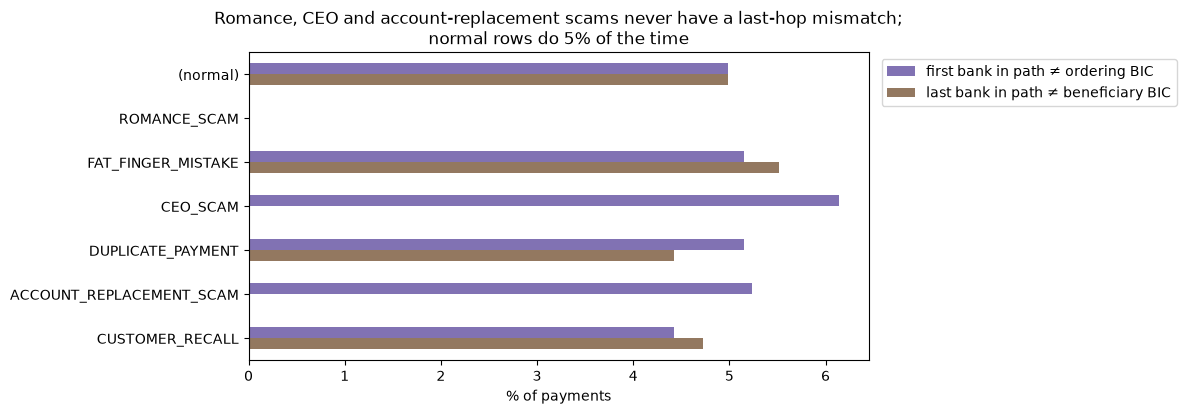

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
(a6.set_index("anomaly_type")[["pct_first_hop_differs", "pct_last_hop_differs"]]
   .rename(columns={"pct_first_hop_differs": "first bank in path ≠ ordering BIC",
                    "pct_last_hop_differs": "last bank in path ≠ beneficiary BIC"})
   .plot.barh(ax=ax, color=["#8172B3", "#937860"]))
ax.set_xlabel("% of payments")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Romance, CEO and account-replacement scams never have a last-hop mismatch;\nnormal rows do 5% of the time")
save(fig, "A6_path_mismatch")
plt.show()

### A7. Duration by anomaly type, controlling for the route (H-A7)

In [22]:
a7 = q("""
    SELECT coalesce(anomaly_type, '(normal)') AS anomaly_type,
           transaction_type_code,
           count(*) AS n,
           median(total_duration) AS median_duration_s
    FROM base
    GROUP BY 1, 2
""")
a7["cell"] = a7.median_duration_s.round().astype(int).astype(str) + "  (n=" + a7.n.astype(str) + ")"
# median seconds (number of payments); compare each row with (normal) in the same column
a7.pivot(index="anomaly_type", columns="transaction_type_code", values="cell")

transaction_type_code,Covered,Direct,Indirect
anomaly_type,,,
(normal),383 (n=415815),39 (n=6318885),281 (n=3258294)
ACCOUNT_REPLACEMENT_SCAM,333 (n=3),454 (n=443),999 (n=203)
CEO_SCAM,72 (n=7),648 (n=592),930 (n=346)
CUSTOMER_RECALL,539 (n=15),41 (n=187),96 (n=115)
DUPLICATE_PAYMENT,589 (n=31),50 (n=408),480 (n=240)
FAT_FINGER_MISTAKE,584 (n=88),40 (n=1271),232 (n=581)
ROMANCE_SCAM,989 (n=3),1102 (n=1494),1402 (n=979)


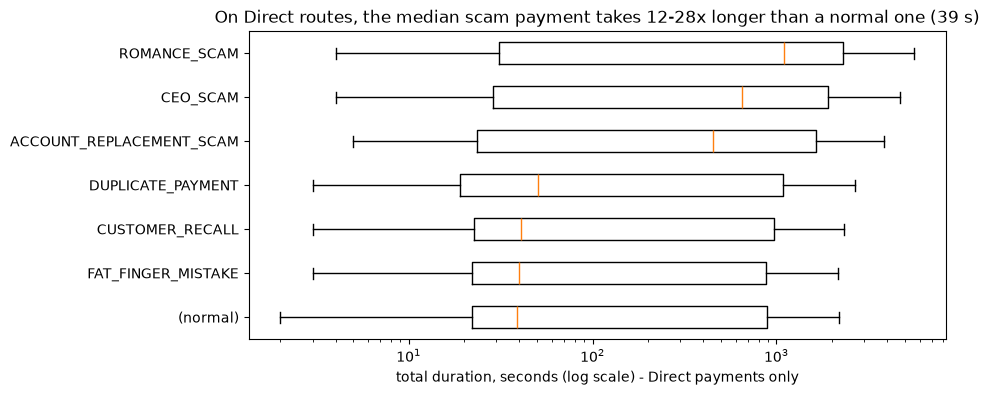

In [23]:
direct = q("""
    SELECT coalesce(anomaly_type, '(normal)') AS anomaly_type, total_duration
    FROM base
    WHERE transaction_type_code = 'Direct'
      AND (anomaly_type IS NOT NULL OR row_id % 200 = 0)   -- all anomalies + 0.5% sample of normal
""")
order = direct.groupby("anomaly_type").total_duration.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([direct.loc[direct.anomaly_type == k, "total_duration"] for k in order],
           orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xscale("log")
ax.set_xlabel("total duration, seconds (log scale) - Direct payments only")
ax.set_title("On Direct routes, the median scam payment takes 12-28x longer than a normal one (39 s)")
save(fig, "A7_duration_by_type")
plt.show()

### A8. Fat-finger mistakes: how the separator moved (H-A8)
The brief says the comma separator is put in the wrong place. Two tests:
1. **Copy test:** is the wrong amount an exact power-of-10 copy (×10, ×100, ÷10 ...) of another normal payment to the same payee?
2. **Digit test:** in **USD** payments there is no currency conversion, so the typed digits survive. Moving the decimal point to the right turns the cents into trailing zeros (`8,680.20` → `868,020.00`), so a fat-finger amount that is too large should usually be a whole-dollar amount.

In [24]:
a8_copy = q("""
    WITH s AS (   -- fat-finger rows + a 0.05% sample of normal rows as the baseline
        SELECT row_id, coalesce(anomaly_type, '(normal sample)') AS kind,
               ordering_account, beneficiary_account, usd_amount
        FROM base
        WHERE anomaly_type = 'FAT_FINGER_MISTAKE'
           OR (anomaly_type IS NULL AND row_id % 2000 = 0)
    ),
    m AS (        -- compare with every OTHER normal payment of the same sender -> receiver pair
        SELECT s.row_id, s.kind,
               min(abs(log10(s.usd_amount / n.usd_amount) - round(log10(s.usd_amount / n.usd_amount))))
                   FILTER (WHERE round(log10(s.usd_amount / n.usd_amount)) <> 0) AS best_dev
        FROM s
        JOIN base n
          ON n.ordering_account = s.ordering_account
         AND n.beneficiary_account = s.beneficiary_account
         AND n.anomaly_type IS NULL
         AND n.row_id <> s.row_id
        GROUP BY 1, 2
    )
    SELECT kind,
           count(*)                                    AS rows_with_pair_history,
           count(*) FILTER (WHERE best_dev < 0.001)    AS exact_power_of_10_copy,
           round(100 * count(*) FILTER (WHERE best_dev < 0.001) / count(*), 1) AS pct_exact_copy
    FROM m
    GROUP BY 1
    ORDER BY 1
""")
a8_copy  # best_dev < 0.001 means the ratio is within 0.23% of an exact power of 10

,kind,rows_with_pair_history,exact_power_of_10_copy,pct_exact_copy
0,(normal sample),1193,41,3.4
1,FAT_FINGER_MISTAKE,460,14,3.0


In [25]:
# Number of trailing zeros of the amount written in cents: 0 = has cents (e.g. 1234.56),
# 2 = whole dollars (1234.00), 3 = whole tens (1230.00), ...
TRAILING_ZEROS = "CASE " + " ".join(f"WHEN cents % {10 ** k} = 0 THEN {k}" for k in range(8, 0, -1)) + " ELSE 0 END"

a8_usd = q(f"""
    WITH b AS (
        SELECT coalesce(anomaly_type, '(normal USD)') AS kind,
               round(usd_amount * 100)::BIGINT        AS cents
        FROM base
        WHERE currency_code = 'USD'
          AND (anomaly_type = 'FAT_FINGER_MISTAKE' OR anomaly_type IS NULL)
    )
    SELECT kind, {TRAILING_ZEROS} AS trailing_zeros, count(*) AS n
    FROM b
    GROUP BY 1, 2
""")
a8_share = (a8_usd.pivot(index="trailing_zeros", columns="kind", values="n").fillna(0)
                  .pipe(lambda t: t / t.sum() * 100))
whole = a8_share[a8_share.index >= 2].sum().round(1)
a8_pct = a8_share.round(1)
print("% whole-dollar amounts (2+ trailing zeros in cents):")
print(whole.to_string())
a8_pct  # % of each column

% whole-dollar amounts (2+ trailing zeros in cents):
kind
(normal USD)          38.6
FAT_FINGER_MISTAKE    77.5


kind,(normal USD),FAT_FINGER_MISTAKE
trailing_zeros,,
0,55.8,11.4
1,5.6,11.1
2,19.5,26.6
3,3.6,18.7
4,4.2,18.7
5,5.5,3.8
6,4.1,1.6
7,1.5,2.8
8,0.3,5.4


In [26]:
# Direction of the mistake (vs the sender's usual amount) and the zeros it leaves behind
a8_dir = q(f"""
    WITH med AS (
        SELECT ordering_account, median(usd_amount) AS sender_median
        FROM base WHERE anomaly_type IS NULL GROUP BY 1
    ),
    f AS (
        SELECT round(b.usd_amount * 100)::BIGINT          AS cents,
               round(log10(b.usd_amount / m.sender_median)) AS k
        FROM base b JOIN med m USING (ordering_account)
        WHERE b.anomaly_type = 'FAT_FINGER_MISTAKE' AND b.currency_code = 'USD'
    )
    SELECT CASE WHEN k < 0 THEN '1 smaller than usual'
                WHEN k = 0 THEN '2 about the usual size'
                ELSE            '3 larger than usual' END       AS direction,
           count(*)                                            AS n,
           round(100 * avg((cents % 100 = 0)::INT), 1)         AS pct_whole_dollars,
           round(avg({TRAILING_ZEROS}), 2)                     AS avg_trailing_zeros
    FROM f
    GROUP BY 1
    ORDER BY 1
""")
a8_dir

,direction,n,pct_whole_dollars,avg_trailing_zeros
0,1 smaller than usual,78,47.4,1.31
1,2 about the usual size,17,52.9,1.76
2,3 larger than usual,219,90.0,3.48


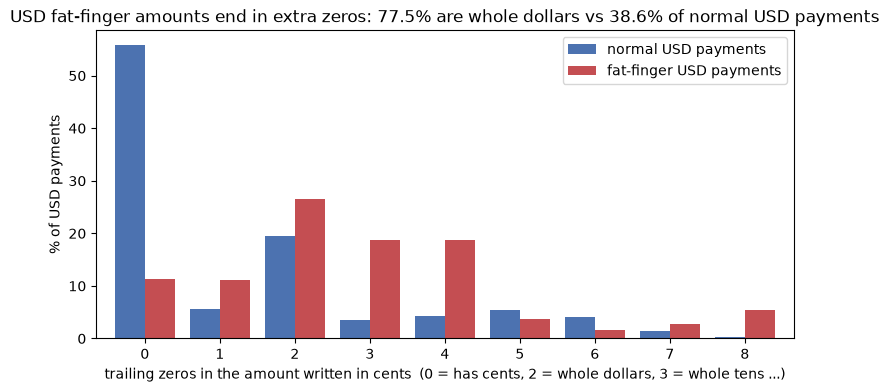

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
a8_pct[["(normal USD)", "FAT_FINGER_MISTAKE"]].plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], width=0.8)
ax.set_xlabel("trailing zeros in the amount written in cents  (0 = has cents, 2 = whole dollars, 3 = whole tens ...)")
ax.set_ylabel("% of USD payments")
ax.tick_params(axis="x", rotation=0)
ax.legend(["normal USD payments", "fat-finger USD payments"])
ax.set_title(f"USD fat-finger amounts end in extra zeros: {whole['FAT_FINGER_MISTAKE']:.1f}% are whole dollars "
             f"vs {whole['(normal USD)']:.1f}% of normal USD payments")
save(fig, "A8_fat_finger_trailing_zeros")
plt.show()

### A9. Amount compared with the sender's usual amount (H-A9)
Account-replacement scams intercept a **real invoice**, so the amount should look like the sender's normal payments. CEO scams are an **illegitimate request** from "the boss", so the amount may be unusually large. The baseline is each sender's median normal payment.

In [28]:
a9 = q("""
    WITH med AS (
        SELECT ordering_account, median(usd_amount) AS sender_median
        FROM base WHERE anomaly_type IS NULL GROUP BY 1
    )
    SELECT coalesce(b.anomaly_type, '(normal sample)') AS kind,
           b.ordering_type,
           b.usd_amount / m.sender_median            AS ratio
    FROM base b
    JOIN med m USING (ordering_account)
    WHERE b.anomaly_type IS NOT NULL
       OR (b.anomaly_type IS NULL AND b.row_id % 200 = 0)   -- 0.5% sample of normal payments
""")
# extra baseline for CEO scams: normal payments sent by businesses only
a9_all = pd.concat([a9, a9[(a9.kind == "(normal sample)") & (a9.ordering_type == "B")]
                        .assign(kind="(normal sample, business senders)")])


def ratio_summary(r: pd.Series) -> pd.Series:
    return pd.Series({
        "n": len(r),
        "median_ratio": r.median(),
        "p25": r.quantile(0.25),
        "p75": r.quantile(0.75),
        "pct_above_usual": 100 * (r > 1).mean(),
        "pct_over_10x": 100 * (r > 10).mean(),
        "pct_over_100x": 100 * (r > 100).mean(),
    })


a9_summary = a9_all.groupby("kind")["ratio"].apply(ratio_summary).unstack().round(2)
a9_summary["n"] = a9_summary["n"].astype(int)
a9_summary  # ratio = amount / sender's median normal amount (1 = exactly the usual amount)

,n,median_ratio,p25,p75,pct_above_usual,pct_over_10x,pct_over_100x
kind,,,,,,,
(normal sample),49968,1.00,0.24,4.19,48.49,14.52,1.95
"(normal sample, business senders)",39349,1.00,0.23,4.37,49.21,14.86,2.02
ACCOUNT_REPLACEMENT_SCAM,639,1.10,0.23,4.62,52.11,16.43,1.72
CEO_SCAM,916,3.15,0.41,39.65,64.85,37.23,20.52
CUSTOMER_RECALL,316,0.87,0.24,4.05,48.10,15.82,3.16
DUPLICATE_PAYMENT,673,0.86,0.19,3.04,47.10,11.00,1.93
FAT_FINGER_MISTAKE,1919,83.45,1.90,1622.85,76.81,65.82,48.57
ROMANCE_SCAM,791,1.26,0.14,6.77,53.10,20.35,4.42


In [29]:
# Is the scam amount an exact copy of an amount the sender really paid before (to anyone)?
a9_copy = q("""
    WITH s AS (
        SELECT row_id, coalesce(anomaly_type, '(normal sample)') AS kind, ordering_account, usd_amount
        FROM base
        WHERE anomaly_type IN ('ACCOUNT_REPLACEMENT_SCAM', 'CEO_SCAM')
           OR (anomaly_type IS NULL AND row_id % 500 = 0)
    )
    SELECT kind,
           count(*)                           AS rows_with_sender_history,
           round(100 * avg(has_same::INT), 2) AS pct_same_amount_paid_before
    FROM (
        SELECT s.row_id, s.kind, bool_or(n.usd_amount = s.usd_amount) AS has_same
        FROM s
        JOIN base n
          ON n.ordering_account = s.ordering_account
         AND n.anomaly_type IS NULL
         AND n.row_id <> s.row_id
        GROUP BY 1, 2
    )
    GROUP BY 1
    ORDER BY 1
""")
a9_copy

,kind,rows_with_sender_history,pct_same_amount_paid_before
0,(normal sample),19734,3.15
1,ACCOUNT_REPLACEMENT_SCAM,639,2.19
2,CEO_SCAM,916,1.64


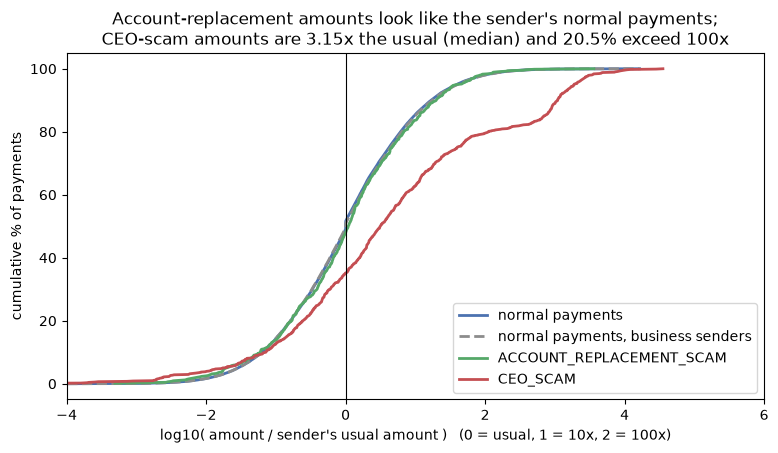

In [30]:
fig, ax = plt.subplots(figsize=(9, 4.5))
styles = [("(normal sample)", "#4C72B0", "normal payments"),
          ("(normal sample, business senders)", "#8C8C8C", "normal payments, business senders"),
          ("ACCOUNT_REPLACEMENT_SCAM", "#55A868", "ACCOUNT_REPLACEMENT_SCAM"),
          ("CEO_SCAM", "#C44E52", "CEO_SCAM")]
for kind, color, label in styles:
    r = np.sort(np.log10(a9_all.loc[a9_all.kind == kind, "ratio"].to_numpy()))
    ax.plot(r, np.arange(1, len(r) + 1) / len(r) * 100, color=color, lw=2, label=label,
            ls="--" if "business" in kind else "-")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-4, 6)
ax.set_xlabel("log10( amount / sender's usual amount )   (0 = usual, 1 = 10x, 2 = 100x)")
ax.set_ylabel("cumulative % of payments")
ax.legend(loc="lower right")
ceo = a9_summary.loc["CEO_SCAM"]
ax.set_title(f"Account-replacement amounts look like the sender's normal payments;\n"
             f"CEO-scam amounts are {ceo.median_ratio:.2f}x the usual (median) and {ceo.pct_over_100x:.1f}% exceed 100x")
save(fig, "A9_amount_vs_usual")
plt.show()

### A10. Duplicates: what exactly is copied? (H-A10)
A3 showed that "same sender, receiver, amount and currency within 2 hours" explains most duplicate labels but not all (139 unlabelled groups also repeat within 2 hours). A back-office race condition re-sends the **whole message**, so a true duplicate should also repeat the **bank path** and the **settlement duration**.

In [31]:
# Rows that belong to any repeat group (same sender, receiver, amount, currency). This keeps the 6-column test small and fast.
con.execute("""
    CREATE OR REPLACE TEMP TABLE rep_rows AS
    SELECT b.*
    FROM base b
    SEMI JOIN (SELECT ordering_account, beneficiary_account, usd_amount, currency_code
               FROM base GROUP BY ALL HAVING count(*) > 1) g
    USING (ordering_account, beneficiary_account, usd_amount, currency_code)
""")

a10 = q("""
    WITH g AS (   -- copies identical in all 6 fields
        SELECT ordering_account, beneficiary_account, usd_amount, currency_code, bic8_path, total_duration,
               count(*)                                                   AS n_copies,
               count(*) FILTER (WHERE anomaly_type = 'DUPLICATE_PAYMENT') AS n_dup,
               count(*) FILTER (WHERE anomaly_type = 'ROMANCE_SCAM')      AS n_romance,
               max(ep) - min(ep)                                          AS spread_s
        FROM rep_rows
        GROUP BY ALL
        HAVING count(*) > 1
    )
    SELECT CASE WHEN n_dup = n_copies THEN 'labelled DUPLICATE_PAYMENT'
                WHEN n_dup > 0        THEN 'partly labelled DUPLICATE_PAYMENT'
                WHEN n_romance > 0    THEN 'labelled ROMANCE_SCAM'
                ELSE                       'unlabelled' END AS label,
           spread_s <= 2 * 3600                             AS within_2h,
           count(*)                                         AS n_groups,
           sum(n_copies)                                    AS n_rows,
           max(spread_s)                                    AS max_spread_s
    FROM g
    GROUP BY 1, 2
    ORDER BY 1, 2
""")
a10  # groups of payments identical in sender, receiver, amount, currency, bank path AND duration

,label,within_2h,n_groups,n_rows,max_spread_s
0,labelled DUPLICATE_PAYMENT,True,185,679.0,7043
1,labelled ROMANCE_SCAM,True,10,22.0,1223
2,unlabelled,False,80,164.0,6697352
3,unlabelled,True,5,10.0,4089


In [32]:
# Coverage: how many DUPLICATE_PAYMENT rows have an identical copy (all 6 fields) within 2 hours?
coverage = q("""
    SELECT count(DISTINCT r.row_id)                                         AS duplicate_rows,
           count(DISTINCT CASE WHEN x.row_id IS NOT NULL THEN r.row_id END) AS with_identical_copy_within_2h
    FROM rep_rows r
    LEFT JOIN rep_rows x
      ON  x.row_id <> r.row_id
      AND x.ordering_account = r.ordering_account AND x.beneficiary_account = r.beneficiary_account
      AND x.usd_amount = r.usd_amount             AND x.currency_code = r.currency_code
      AND x.bic8_path = r.bic8_path               AND x.total_duration = r.total_duration
      AND abs(x.ep - r.ep) <= 2 * 3600
    WHERE r.anomaly_type = 'DUPLICATE_PAYMENT'
""")
rule = a10[a10.within_2h]
tp = int(rule.loc[rule.label == "labelled DUPLICATE_PAYMENT", "n_groups"].sum())
fp = int(rule.loc[rule.label == "unlabelled", "n_groups"].sum())
print(f"Rule matches {tp} labelled duplicate groups and {fp} unlabelled groups "
      f"-> precision {100 * tp / (tp + fp):.1f}% (romance repeats excluded: they already carry a label)")
coverage

Rule matches 185 labelled duplicate groups and 5 unlabelled groups -> precision 97.4% (romance repeats excluded: they already carry a label)


,duplicate_rows,with_identical_copy_within_2h
0,679,679


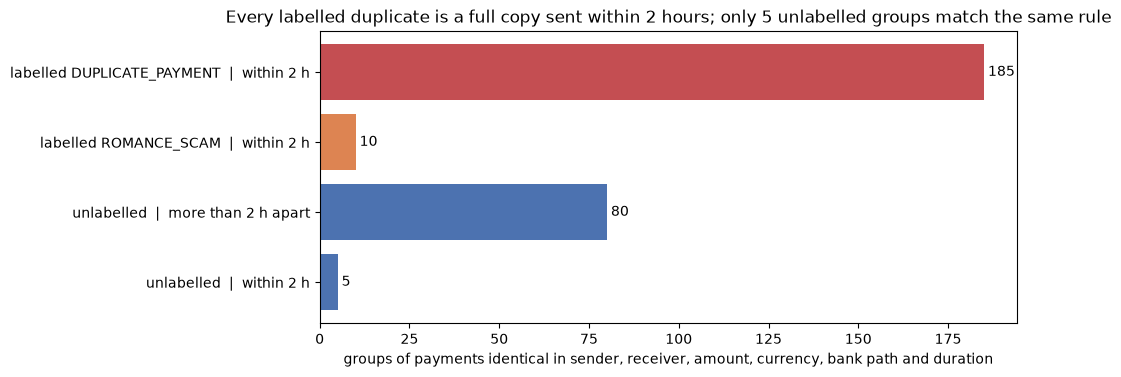

In [33]:
fig, ax = plt.subplots(figsize=(9, 3.8))
d = a10.assign(group=a10.label + np.where(a10.within_2h, "  |  within 2 h", "  |  more than 2 h apart"))
colors = ["#C44E52" if "DUPLICATE" in g else "#DD8452" if "ROMANCE" in g else "#4C72B0" for g in d.group]
ax.barh(d.group, d.n_groups, color=colors)
for y, v in enumerate(d.n_groups):
    ax.text(v, y, f" {v}", va="center")
ax.invert_yaxis()
ax.set_xlabel("groups of payments identical in sender, receiver, amount, currency, bank path and duration")
ax.set_title(f"Every labelled duplicate is a full copy sent within 2 hours; only {fp} unlabelled groups match the same rule")
save(fig, "A10_duplicate_rule")
plt.show()

### A11. CUSTOMER_RECALL: does it differ from normal payments? (H-A11)
Not defined in the brief. We compare its 317 rows with all normal payments on every structured attribute. With this many comparisons, a difference only counts if it passes a Bonferroni-corrected threshold (0.05 divided by the number of tests).

Note for the duration table below: romance rows come in 500 bursts and duplicate rows in 185 copy groups, so their rows are not independent and their z-values overstate the certainty. CUSTOMER_RECALL rows are independent payments.

In [34]:
from math import erfc, sqrt

cr = q("""
    SELECT coalesce(anomaly_type, '(normal)')                                    AS kind,
           count(*)                                                              AS n,
           avg((NOT continuity_qflag)::INT)                                      AS path_has_gap,
           avg((transaction_type_code = 'Direct')::INT)                          AS route_direct,
           avg((transaction_type_code = 'Covered')::INT)                         AS route_covered,
           avg((currency_code = 'USD')::INT)                                     AS currency_usd,
           avg((currency_code = 'EUR')::INT)                                     AS currency_eur,
           avg((substr(ordering_bic8, 5, 2) = substr(beneficiary_bic8, 5, 2))::INT) AS domestic,
           avg((ordering_type = 'C')::INT)                                       AS sender_consumer,
           avg((beneficiary_type = 'C')::INT)                                    AS receiver_consumer,
           avg((usd_amount = round(usd_amount))::INT)                            AS whole_dollar_amount,
           avg((split_part(bic8_path, ';', 1) <> ordering_bic8)::INT)            AS first_hop_differs,
           avg((string_split(bic8_path, ';')[-1] <> beneficiary_bic8)::INT)      AS last_hop_differs,
           avg((dayofweek(ts) IN (0, 6))::INT)                                   AS weekend,
           avg(participant_count)                                                AS avg_banks,
           avg(currency_conversion_count)                                        AS avg_conversions,
           median(usd_amount)                                                    AS median_usd
    FROM base
    WHERE anomaly_type = 'CUSTOMER_RECALL' OR anomaly_type IS NULL
    GROUP BY 1
""").set_index("kind")

rec, nor = cr.loc["CUSTOMER_RECALL"], cr.loc["(normal)"]
share_cols = [c for c in cr.columns if c not in ("n", "avg_banks", "avg_conversions", "median_usd")]
alpha = 0.05 / len(share_cols)
rows = []
for c in share_cols:
    p0, p1, n1 = nor[c], rec[c], rec["n"]
    z = (p1 - p0) / sqrt(p0 * (1 - p0) / n1)
    p = erfc(abs(z) / sqrt(2))
    rows.append({"attribute": c, "normal_%": 100 * p0, "recall_%": 100 * p1, "z": z, "p_value": p,
                 "significant_after_correction": p < alpha})
cr_test = pd.DataFrame(rows).round({"normal_%": 1, "recall_%": 1, "z": 2, "p_value": 4})
print(f"Bonferroni threshold: p < {alpha:.4f} ({len(share_cols)} tests)")
print(cr[["avg_banks", "avg_conversions", "median_usd"]].round(2).to_string())
cr_test

Bonferroni threshold: p < 0.0042 (12 tests)
                 avg_banks  avg_conversions  median_usd
kind                                                   
(normal)              2.58             1.34     3662.58
CUSTOMER_RECALL       2.62             1.39     3163.97


,attribute,normal_%,recall_%,z,p_value,significant_after_correction
0,path_has_gap,7.7,11.0,2.25,0.0242,False
1,route_direct,63.2,59.0,-1.57,0.1172,False
2,route_covered,4.2,4.7,0.51,0.6108,False
3,currency_usd,17.0,16.1,-0.45,0.6548,False
4,currency_eur,32.0,29.7,-0.89,0.3718,False
5,domestic,7.1,5.4,-1.21,0.2253,False
6,sender_consumer,21.2,22.4,0.51,0.6132,False
7,receiver_consumer,71.2,73.2,0.79,0.4311,False
8,whole_dollar_amount,7.4,7.6,0.12,0.9078,False
9,first_hop_differs,5.0,4.4,-0.47,0.6418,False


In [35]:
# Is a recalled payment "stopped part-way" (shorter duration)? Compare with the normal median
# for the SAME route type and the SAME number of banks. Without an effect, about 50% are faster.
a11_dur = q("""
    WITH nm AS (
        SELECT transaction_type_code, participant_count, median(total_duration) AS normal_median
        FROM base WHERE anomaly_type IS NULL GROUP BY 1, 2
    )
    SELECT b.anomaly_type,
           count(*)                                                AS n,
           round(100 * avg((b.total_duration < nm.normal_median)::INT), 1) AS pct_faster_than_normal_median
    FROM base b JOIN nm USING (transaction_type_code, participant_count)
    WHERE b.anomaly_type IS NOT NULL
    GROUP BY 1
    ORDER BY 3
""")
a11_dur["z_vs_50pct"] = ((a11_dur.pct_faster_than_normal_median / 100 - 0.5) / np.sqrt(0.25 / a11_dur.n)).round(2)
a11_dur

,anomaly_type,n,pct_faster_than_normal_median,z_vs_50pct
0,ROMANCE_SCAM,2476,26.3,-23.59
1,CEO_SCAM,945,34.6,-9.47
2,ACCOUNT_REPLACEMENT_SCAM,649,36.8,-6.73
3,DUPLICATE_PAYMENT,679,41.4,-4.48
4,FAT_FINGER_MISTAKE,1940,49.0,-0.88
5,CUSTOMER_RECALL,317,51.1,0.39


### A12. Time of day and weekday per anomaly type (H-A12)
Hypothesis: some anomalies happen at unusual times (e.g. scams at night or at weekends). Hours are in **UTC** (set in the setup cell).

In [36]:
time_cols = """
           count(*)                                          AS n,
           round(100 * avg((hour(ts) BETWEEN 0 AND 5)::INT), 1)   AS pct_00_05h,
           round(100 * avg((hour(ts) BETWEEN 6 AND 11)::INT), 1)  AS pct_06_11h,
           round(100 * avg((hour(ts) BETWEEN 12 AND 17)::INT), 1) AS pct_12_17h,
           round(100 * avg((hour(ts) BETWEEN 18 AND 23)::INT), 1) AS pct_18_23h,
           round(100 * avg((dayofweek(ts) IN (0, 6))::INT), 1)    AS pct_weekend
"""
a12 = q(f"""
    SELECT coalesce(anomaly_type, '(normal)') AS kind, {time_cols}
    FROM base GROUP BY 1
    UNION ALL
    SELECT '(normal, business senders)', {time_cols}
    FROM base WHERE anomaly_type IS NULL AND ordering_type = 'B'
    UNION ALL
    SELECT '(normal, consumer senders)', {time_cols}
    FROM base WHERE anomaly_type IS NULL AND ordering_type = 'C'
    ORDER BY n DESC
""")
a12  # % of each row's payments in each UTC time band; compare every row with (normal)

,kind,n,pct_00_05h,pct_06_11h,pct_12_17h,pct_18_23h,pct_weekend
0,(normal),9992994,15.5,28.0,32.7,23.8,11.2
1,"(normal, business senders)",7870850,15.6,28.2,32.6,23.6,11.2
2,"(normal, consumer senders)",2122144,15.3,27.4,32.8,24.4,11.2
3,ROMANCE_SCAM,2476,19.8,32.6,27.7,19.9,12.9
4,FAT_FINGER_MISTAKE,1940,15.9,27.9,33.2,22.9,11.0
5,CEO_SCAM,945,13.3,29.1,33.7,23.9,12.3
6,DUPLICATE_PAYMENT,679,16.2,27.2,31.5,25.0,12.4
7,ACCOUNT_REPLACEMENT_SCAM,649,14.5,24.8,36.1,24.7,10.5
8,CUSTOMER_RECALL,317,17.4,26.8,31.5,24.3,9.8


### A13. Results → final rules (verified on all 10,000,000 rows)

| ID | Rule (condition → effect → size → rows covered) | Evidence | Confidence |
|---|---|---|---|
| R-A1 | ROMANCE_SCAM → sender is a **Consumer in 100%** of rows (2,476/2,476; normal 21.2%). CEO_SCAM → sender is a **Business in 100%** (945/945). The other 4 types copy the normal mix (19.7-22.4% consumer senders). | A1 | High |
| R-A2 | ROMANCE_SCAM = **500 victims, each paying exactly 1 beneficiary 2-8 times** (median 5) within **18 min** (median; 90% within 40 min). **83.1%** of consecutive payments are larger than the previous one; the median amount rises from **$33 (1st) to $1,925 (8th)**. 378 beneficiaries, 90 of them receive from 2-6 victims. | A2 | High |
| R-A3 | DUPLICATE_PAYMENT = **185 groups of 2-5 copies identical in sender account, receiver account, USD amount, currency, bank path and duration**, all sent within **2 hours** (203 s - 7,043 s; median 67 min). **Every copy is labelled, including the first** (679/679). Reverse check: only **5 unlabelled groups (10 rows)** meet the same rule → **97.4% precision** (10 romance-repeat groups already carry the romance label). | A3, A10 | High |
| R-A4 | FAT_FINGER_MISTAKE amounts are **≥ ~30x away** from the sender's usual (median normal) amount in **71.5%** of rows (normal: ≈11.5%); **72.5% too large, 20.5% too small**. The 12 largest payments in the dataset are all fat-finger. | A4 | High |
| R-A5 | Mechanism: in **USD** payments (no currency conversion, so the typed digits survive) **77.5% of fat-finger amounts are whole dollars vs 38.6% of normal USD payments**. When the amount is too large (219 rows), **90.0%** are whole dollars with 3.5 trailing zeros on average (in cents), the trace of a decimal point moved to the right (`8,680.20` → `868,020.00`). | A8 | Medium-high: visible in USD only; currency conversion hides the digits elsewhere |
| R-A6 | CEO, account-replacement and romance scams go to a payee the sender **never paid normally** (0.2% / 0% / 0% have pair history, vs 23.6% of normal payments). Fat-finger, duplicate and recall rows (19.6-26.8%) look like normal relationships. | A5 | High |
| R-A7 | ACCOUNT_REPLACEMENT_SCAM amounts follow the **sender's normal amount distribution**: median **1.10x** the usual amount, middle half 0.23-4.62x (normal: 1.00x, 0.24-4.19x). The scam reuses a realistic invoice amount and only swaps the account. | A9 | High |
| R-A8 | CEO_SCAM amounts are **larger than the company's usual**: median **3.15x**, **37.2% over 10x** and **20.5% over 100x** (normal business payments: ≈14.9% and ≈2.0%). | A9 | High |
| R-A9 | Romance, CEO and account-replacement rows **never** have a last-hop mismatch (0%, vs 4.99% of normal rows); romance rows never have a first-hop mismatch either. *Interpretation:* the fraudster side of these rows is generated separately, without the endpoint noise added to normal traffic. | A6 | High (observation) / Medium (interpretation) |
| R-A10 | Scams settle slower **on the same route**: Direct median **39 s normal vs 454 s (account replacement), 648 s (CEO), 1,102 s (romance)**; same on Indirect. Controlling for route type **and** number of banks, only 26.3% (romance), 34.6% (CEO) and 36.8% (account replacement) are faster than the normal median (50% expected). Fat-finger and recall ≈ normal (Direct 40 s and 41 s; 49.0% and 51.1% faster than the normal median). Duplicates are slightly slower (Direct 50 s; 41.4% faster), weak evidence because the copies in a group share one duration. | A7, A11 | High for Direct/Indirect; Covered has only 3-7 scam rows |

**Hypotheses that did not hold (reported on purpose - the rubric rewards them):**
- H-A2 "amounts rise every time": only **44.8%** of victims have strictly rising amounts; the rise is a strong trend (83.1% of steps), not a strict rule.
- Brief vs data: romance beneficiaries are "another Consumer" in the brief, but **26.9% are Businesses**.
- H-A3 "same amount within 2 hours = duplicate": 139 unlabelled groups also do this. Adding **bank path and duration** (H-A10) reduces the exceptions to 5 groups.
- H-A8 copy test: fat-finger amounts are **not** power-of-10 copies of an earlier payment to the same payee (3.0% vs ≈3.4% for normal payments).
- Account-replacement and CEO amounts are **not** copies of an amount the sender paid before (2.2% / 1.6% vs ≈3.2% baseline).
- H-A11 CUSTOMER_RECALL: **no attribute differs** after correction for 12 tests. The smallest p-value is 0.024 (path gaps 11.0% vs 7.7%), above the 0.0042 threshold. Duration with route and banks controlled: 51.1% faster (≈50% expected), so the "stopped part-way" idea is rejected.
- H-A12 time: **no strong time effect**. Every anomaly type is within about 5 points of normal in every UTC time band and at weekends. Romance is slightly more frequent 00-11 UTC (52.4% vs 43.5%), but its rows come in 500 bursts, so this is weak evidence. Normal business and consumer senders have identical hour profiles.

**Still unexplained:** the generation rule for CUSTOMER_RECALL (question sent to the mentor), and the 5 unlabelled groups that look exactly like duplicates.

*Numbers marked ≈ come from a random 0.5% (A4, A9) or 0.05-0.2% (A8, A9 copy test) sample of normal rows, so a re-run can differ in the last digit.*